# HW11

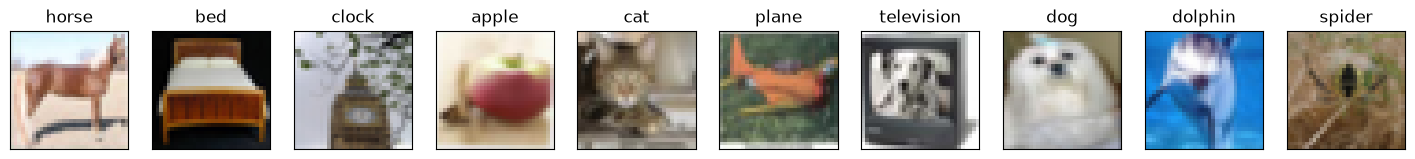

In [1]:
import matplotlib.pyplot as plt

def no_axis_show(img, title="", cmap=None):
  # imshow, and set the interpolation mode to be "nearest"。
  fig = plt.imshow(img, interpolation="nearest", cmap=cmap)
  # do not show the axes in the images.
  fig.axes.get_xaxis().set_visible(False)
  fig.axes.get_yaxis().set_visible(False)
  plt.title(title)

titles = ["horse", "bed", "clock", "apple", "cat", "plane", "television", "dog", "dolphin", "spider"]
plt.figure(figsize=(18, 18))
for i in range(10):
  plt.subplot(1, 10, i+1)
  fig = no_axis_show(plt.imread(f"real_or_drawing/train_data/{i}/{500*i}.bmp"), title=titles[i])

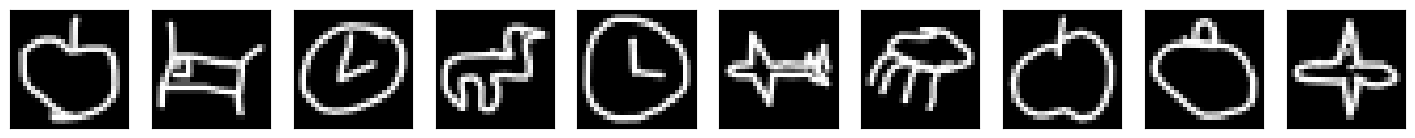

In [2]:
plt.figure(figsize=(18, 18))
for i in range(10):
  plt.subplot(1, 10, i+1)
  fig = no_axis_show(plt.imread(f"real_or_drawing/test_data/0/" + str(i).rjust(5, "0") + ".bmp"))

# Special Domain Knowledge

When we graffiti, we usually draw the outline only, therefore we can perform edge detection processing on the source data to make it more similar to the target data.


## Canny Edge Detection
The implementation of Canny Edge Detection is as follow.
The algorithm will not be describe thoroughly here.  If you are interested, please refer to the wiki or [here](https://medium.com/@pomelyu5199/canny-edge-detector-%E5%AF%A6%E4%BD%9C-opencv-f7d1a0a57d19).

We only need two parameters to implement Canny Edge Detection with CV2:  `low_threshold` and `high_threshold`.

```cv2.Canny(image, low_threshold, high_threshold)```

Simply put, when the edge value exceeds the high_threshold, we determine it as an edge. If the edge value is only above low_threshold, we will then determine whether it is an edge or not.

Let"s implement it on the source data.

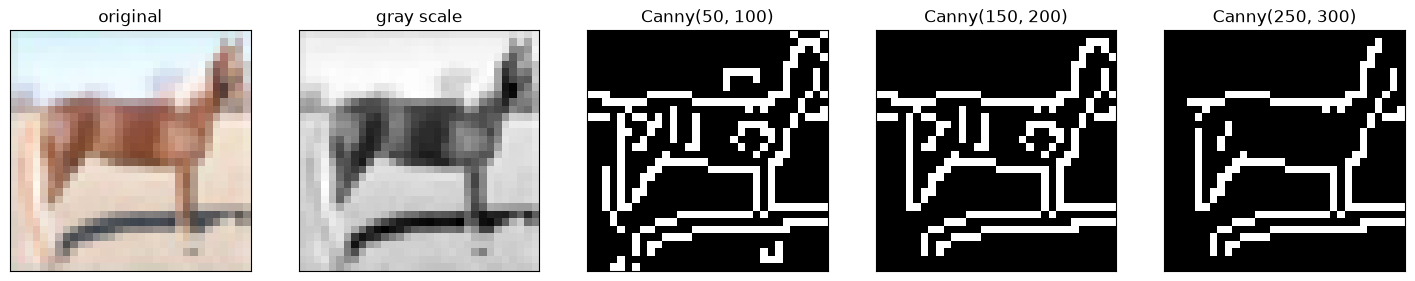

In [3]:
import cv2
import matplotlib.pyplot as plt
titles = ["horse", "bed", "clock", "apple", "cat", "plane", "television", "dog", "dolphin", "spider"]
plt.figure(figsize=(18, 18))

original_img = plt.imread(f"real_or_drawing/train_data/0/0.bmp")
plt.subplot(1, 5, 1)
no_axis_show(original_img, title="original")

gray_img = cv2.cvtColor(original_img, cv2.COLOR_RGB2GRAY)
plt.subplot(1, 5, 2)
no_axis_show(gray_img, title="gray scale", cmap="gray")

gray_img = cv2.cvtColor(original_img, cv2.COLOR_RGB2GRAY)
plt.subplot(1, 5, 2)
no_axis_show(gray_img, title="gray scale", cmap="gray")

canny_50100 = cv2.Canny(gray_img, 50, 100)
plt.subplot(1, 5, 3)
no_axis_show(canny_50100, title="Canny(50, 100)", cmap="gray")

canny_150200 = cv2.Canny(gray_img, 150, 200)
plt.subplot(1, 5, 4)
no_axis_show(canny_150200, title="Canny(150, 200)", cmap="gray")

canny_250300 = cv2.Canny(gray_img, 250, 300)
plt.subplot(1, 5, 5)
no_axis_show(canny_250300, title="Canny(250, 300)", cmap="gray")


# Data Process


The data is suitible for `torchvision.ImageFolder`. You can create a dataset with `torchvision.ImageFolder`. Details for image augmentation please refer to the comments in the following codes.

In [4]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.autograd import Function

import torch.optim as optim
import torchvision.transforms as transforms
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader

source_transform = transforms.Compose([
    # Turn RGB to grayscale. (Bacause Canny do not support RGB images.)
    transforms.Grayscale(),
    # cv2 do not support skimage.Image, so we transform it to np.array,
    # and then adopt cv2.Canny algorithm.
    transforms.Lambda(lambda x: cv2.Canny(np.array(x), 170, 300)),
    # Transform np.array back to the skimage.Image.
    transforms.ToPILImage(),
    # 50% Horizontal Flip. (For Augmentation)
    transforms.RandomHorizontalFlip(),
    # Rotate +- 15 degrees. (For Augmentation), and filled with zero
    # if there"s empty pixel after rotation.
    transforms.RandomRotation(15, fill=(0,)),
    # Transform to tensor for model inputs.
    transforms.ToTensor(),
])
target_transform = transforms.Compose([
    # Turn RGB to grayscale.
    transforms.Grayscale(),
    # Resize: size of source data is 32x32, thus we need to
    #  enlarge the size of target data from 28x28 to 32x32。
    transforms.Resize((32, 32)),
    # 50% Horizontal Flip. (For Augmentation)
    transforms.RandomHorizontalFlip(),
    # Rotate +- 15 degrees. (For Augmentation), and filled with zero
    # if there"s empty pixel after rotation.
    transforms.RandomRotation(15, fill=(0,)),
    # Transform to tensor for model inputs.
    transforms.ToTensor(),
])

source_dataset = ImageFolder("real_or_drawing/train_data", transform=source_transform)
target_dataset = ImageFolder("real_or_drawing/test_data", transform=target_transform)

source_dataloader = DataLoader(source_dataset, batch_size=32, shuffle=True)
target_dataloader = DataLoader(target_dataset, batch_size=32, shuffle=True)
test_dataloader = DataLoader(target_dataset, batch_size=128, shuffle=False)

# Model

In [5]:
class FeatureExtractor(nn.Module):

    def __init__(self):
        super(FeatureExtractor, self).__init__()

        self.conv = nn.Sequential(
            nn.Conv2d(1, 64, 3, 1, 1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(64, 128, 3, 1, 1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2, 2, 0),
            nn.Dropout2d(0.1),

            nn.Conv2d(128, 256, 3, 1, 1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.Conv2d(256, 256, 3, 1, 1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(2, 2, 0),
            nn.Dropout2d(0.1),

            nn.Conv2d(256, 512, 3, 1, 1),
            nn.BatchNorm2d(512),
            nn.ReLU(),

            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(1), 

            # bottleneck
            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
        )

    def forward(self, x):
        return self.conv(x)

class LabelPredictor(nn.Module):

    def __init__(self):
        super(LabelPredictor, self).__init__()

        self.layer = nn.Sequential(
            nn.Linear(256, 256),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(256, 10),
        )

    def forward(self, h):
        c = self.layer(h)
        return c

class DomainClassifier(nn.Module):

    def __init__(self):
        super(DomainClassifier, self).__init__()

        self.layer = nn.Sequential(
            nn.Linear(256, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),

            nn.Linear(512, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),

            nn.Linear(512, 1),
        )

    def forward(self, h):
        y = self.layer(h)
        return y

# Pre-processing

Here we use Adam as our optimizor.

In [6]:
feature_extractor = FeatureExtractor().cuda()
label_predictor = LabelPredictor().cuda()
domain_classifier = DomainClassifier().cuda()

class_criterion = nn.CrossEntropyLoss()
domain_criterion = nn.BCEWithLogitsLoss()

optimizer_F = optim.AdamW(feature_extractor.parameters(), lr=1e-4, weight_decay=1e-2)
optimizer_C = optim.AdamW(label_predictor.parameters(), lr=1e-4, weight_decay=1e-2)
optimizer_D = optim.AdamW(domain_classifier.parameters(), lr=1e-4, weight_decay=1e-2)

# Start Training


## DaNN Implementation

In the original paper, Gradient Reversal Layer is used.
Feature Extractor, Label Predictor, and Domain Classifier are all trained at the same time. In this code, we train Domain Classifier first, and then train our Feature Extractor (same concept as Generator and Discriminator training process in GAN).

## Reminder
* Lambda, which controls the domain adversarial loss, is adaptive in the original paper. You can refer to [the original work](https://arxiv.org/pdf/1505.07818.pdf) . Here lambda is set to 0.1.
* We do not have the label to target data, you can only evaluate your model by uploading your result to kaggle.:)

In [7]:
def train_epoch(source_dataloader, target_dataloader, lamb):
    """
      Args:
        source_dataloader: source data的dataloader
        target_dataloader: target data的dataloader
        lamb: control the balance of domain adaptatoin and classification.
    """

    # D loss: Domain Classifier的loss
    # F loss: Feature Extrator & Label Predictor的loss
    running_D_loss, running_F_loss = 0.0, 0.0
    total_hit, total_num = 0.0, 0.0

    for i, ((source_data, source_label), (target_data, _)) in enumerate(zip(source_dataloader, target_dataloader)):

        source_data = source_data.cuda()
        source_label = source_label.cuda()
        target_data = target_data.cuda()

        # Mixed the source data and target data, or it"ll mislead the running params
        #   of batch_norm. (runnning mean/var of soucre and target data are different.)
        mixed_data = torch.cat([source_data, target_data], dim=0)
        domain_label = torch.zeros([source_data.shape[0] + target_data.shape[0], 1]).cuda()
        # set domain label of source data to be 1.
        domain_label[:source_data.shape[0]] = 1

        # Step 1 : train domain classifier
        feature = feature_extractor(mixed_data)
        # We don"t need to train feature extractor in step 1.
        # Thus we detach the feature neuron to avoid backpropgation.
        domain_logits = domain_classifier(feature.detach())
        loss = domain_criterion(domain_logits, domain_label)
        running_D_loss+= loss.item()
        loss.backward()
        optimizer_D.step()

        # Step 2 : train feature extractor and label classifier
        class_logits = label_predictor(feature[:source_data.shape[0]])
        domain_logits = domain_classifier(feature)
        # loss = cross entropy of classification - lamb * domain binary cross entropy.
        #  The reason why using subtraction is similar to generator loss in disciminator of GAN
        loss = class_criterion(class_logits, source_label) - lamb * domain_criterion(domain_logits, domain_label)
        running_F_loss+= loss.item()
        loss.backward()
        optimizer_F.step()
        optimizer_C.step()

        optimizer_D.zero_grad()
        optimizer_F.zero_grad()
        optimizer_C.zero_grad()

        total_hit += torch.sum(torch.argmax(class_logits, dim=1) == source_label).item()
        total_num += source_data.shape[0]
        print(i, end="\r")

    return running_D_loss / (i+1), running_F_loss / (i+1), total_hit / total_num

EPOCHS = 1000
LAMB_MAX = 0.5
STAGE_EPOCHS = {EPOCHS // 10 - 1: "early", EPOCHS // 2 - 1: "mid", EPOCHS - 1: "final"}

for epoch in range(EPOCHS):

    p = epoch / EPOCHS
    lamb = LAMB_MAX * (2. / (1. + np.exp(-10 * p)) - 1)

    train_D_loss, train_F_loss, train_acc = train_epoch(source_dataloader, target_dataloader, lamb=lamb)

    torch.save(feature_extractor.state_dict(), f"extractor_model.bin")
    torch.save(label_predictor.state_dict(), f"predictor_model.bin")
    if epoch in STAGE_EPOCHS:
        torch.save(feature_extractor.state_dict(), f"extractor_{STAGE_EPOCHS[epoch]}.bin")

    print("epoch {:>3d}: lamb {:.4f}, train D loss: {:6.4f}, train F loss: {:6.4f}, acc {:6.4f}".format(epoch, lamb, train_D_loss, train_F_loss, train_acc))


epoch   0: lamb 0.0000, train D loss: 0.0850, train F loss: 2.0795, acc 0.2482


epoch   1: lamb 0.0025, train D loss: 0.0095, train F loss: 1.8321, acc 0.3458


epoch   2: lamb 0.0050, train D loss: 0.0089, train F loss: 1.7064, acc 0.3972


epoch   3: lamb 0.0075, train D loss: 0.0073, train F loss: 1.6179, acc 0.4362


epoch   4: lamb 0.0100, train D loss: 0.0064, train F loss: 1.5567, acc 0.4536


epoch   5: lamb 0.0125, train D loss: 0.0110, train F loss: 1.5256, acc 0.4662


... (990 outputs left out)

epoch 996: lamb 0.5000, train D loss: 0.6257, train F loss: -0.2580, acc 0.9802


epoch 997: lamb 0.5000, train D loss: 0.6497, train F loss: -0.2613, acc 0.9796


epoch 998: lamb 0.5000, train D loss: 0.6362, train F loss: -0.2631, acc 0.9834


epoch 999: lamb 0.5000, train D loss: 0.6411, train F loss: -0.2641, acc 0.9814


# Inference

We use pandas to generate our csv file.

BTW, the performance of the model trained for 200 epoches might be unstable. You can train for more epoches for a more stable performance.

In [8]:
result = []
label_predictor.eval()
feature_extractor.eval()
for i, (test_data, _) in enumerate(test_dataloader):
    test_data = test_data.cuda()

    class_logits = label_predictor(feature_extractor(test_data))

    x = torch.argmax(class_logits, dim=1).cpu().detach().numpy()
    result.append(x)

import pandas as pd
result = np.concatenate(result)

# Generate your submission
df = pd.DataFrame({"id": np.arange(0,len(result)), "label": result})
df.to_csv("DaNN_submission.csv",index=False)

In [9]:
target_eval_transform = transforms.Compose([
    transforms.Grayscale(),
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
])
target_eval_dataset = ImageFolder("real_or_drawing/test_data", transform=target_eval_transform)
test_eval_dataloader = DataLoader(target_eval_dataset, batch_size=128, shuffle=False)

def balance_predict(probs):
    return (probs / probs.mean(0, keepdims=True)).argmax(1)

label_predictor.eval()
feature_extractor.eval()
probs = []
with torch.no_grad():
    for test_data, _ in test_eval_dataloader:
        logits = label_predictor(feature_extractor(test_data.cuda()))
        probs.append(F.softmax(logits, dim=1).cpu().numpy())
probs = np.concatenate(probs)

result_balanced = balance_predict(probs)
print("argmax class counts:", np.bincount(probs.argmax(1), minlength=10))
print("balanced class counts:", np.bincount(result_balanced, minlength=10))

df = pd.DataFrame({"id": np.arange(0, len(result_balanced)), "label": result_balanced})
df.to_csv("DaNN_balanced_submission.csv", index=False)

argmax class counts: [ 9738  8255 10371 10521 10716 11578  9643  9269 10526  9383]
balanced class counts: [ 9745  8340 10362 10503 10604 11481  9638  9354 10490  9483]


# Visualization
We use t-SNE plot to observe the distribution of extracted features.

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import manifold

## Step1: Load checkpoint and evaluate to get extracted features

In [11]:
from torch.utils.data import Subset

STAGES = ["early", "mid", "final"]
titles = ["horse", "bed", "clock", "apple", "cat", "plane", "television", "dog", "dolphin", "spider"]

source_eval_transform = transforms.Compose([
    transforms.Grayscale(),
    transforms.Lambda(lambda x: cv2.Canny(np.array(x), 170, 300)),
    transforms.ToPILImage(),
    transforms.ToTensor(),
])
source_eval_dataset = ImageFolder("real_or_drawing/train_data", transform=source_eval_transform)
source_eval_loader = DataLoader(source_eval_dataset, batch_size=128, shuffle=False)

rng = np.random.default_rng(0)
target_idx = rng.choice(len(target_eval_dataset), 5000, replace=False)
target_sub_loader = DataLoader(Subset(target_eval_dataset, target_idx), batch_size=128, shuffle=False)

@torch.no_grad()
def extract_features(extractor, loader):
    extractor.eval()
    feats, labels = [], []
    for x, y in loader:
        feats.append(extractor(x.cuda()).cpu().numpy())
        labels.append(y.numpy())
    return np.concatenate(feats), np.concatenate(labels)

stage_feats = {}
for stage in STAGES:
    extractor = FeatureExtractor().cuda()
    extractor.load_state_dict(torch.load(f"extractor_{stage}.bin"))
    src_X, src_y = extract_features(extractor, source_eval_loader)
    tgt_X, _ = extract_features(extractor, target_sub_loader)
    stage_feats[stage] = (src_X, src_y, tgt_X)
    print(stage, src_X.shape, tgt_X.shape)

early (5000, 256) (5000, 256)


mid (5000, 256) (5000, 256)


final (5000, 256) (5000, 256)


## Step2: Apply t-SNE and normalize

In [12]:
def tsne_norm(X):
    X_tsne = manifold.TSNE(n_components=2, init="random", random_state=5, verbose=1).fit_transform(X)
    x_min, x_max = X_tsne.min(0), X_tsne.max(0)
    return (X_tsne - x_min) / (x_max - x_min)

tsne_class, tsne_domain = {}, {}
for stage, (src_X, src_y, tgt_X) in stage_feats.items():
    tsne_class[stage] = tsne_norm(src_X)
    tsne_domain[stage] = tsne_norm(np.concatenate([src_X, tgt_X]))

[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 5000 samples in 0.001s...


[t-SNE] Computed neighbors for 5000 samples in 0.220s...
[t-SNE] Computed conditional probabilities for sample 1000 / 5000
[t-SNE] Computed conditional probabilities for sample 2000 / 5000
[t-SNE] Computed conditional probabilities for sample 3000 / 5000
[t-SNE] Computed conditional probabilities for sample 4000 / 5000
[t-SNE] Computed conditional probabilities for sample 5000 / 5000
[t-SNE] Mean sigma: 2.879716


[t-SNE] KL divergence after 250 iterations with early exaggeration: 84.903069


[t-SNE] KL divergence after 1000 iterations: 2.065395
[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 10000 samples in 0.001s...


[t-SNE] Computed neighbors for 10000 samples in 0.224s...
[t-SNE] Computed conditional probabilities for sample 1000 / 10000
[t-SNE] Computed conditional probabilities for sample 2000 / 10000
[t-SNE] Computed conditional probabilities for sample 3000 / 10000
[t-SNE] Computed conditional probabilities for sample 4000 / 10000
[t-SNE] Computed conditional probabilities for sample 5000 / 10000
[t-SNE] Computed conditional probabilities for sample 6000 / 10000
[t-SNE] Computed conditional probabilities for sample 7000 / 10000
[t-SNE] Computed conditional probabilities for sample 8000 / 10000
[t-SNE] Computed conditional probabilities for sample 9000 / 10000
[t-SNE] Computed conditional probabilities for sample 10000 / 10000
[t-SNE] Mean sigma: 2.527587


[t-SNE] KL divergence after 250 iterations with early exaggeration: 91.440506


... (7 outputs left out)

[t-SNE] KL divergence after 1000 iterations: 1.679149
[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 10000 samples in 0.001s...


[t-SNE] Computed neighbors for 10000 samples in 0.393s...
[t-SNE] Computed conditional probabilities for sample 1000 / 10000
[t-SNE] Computed conditional probabilities for sample 2000 / 10000
[t-SNE] Computed conditional probabilities for sample 3000 / 10000
[t-SNE] Computed conditional probabilities for sample 4000 / 10000
[t-SNE] Computed conditional probabilities for sample 5000 / 10000
[t-SNE] Computed conditional probabilities for sample 6000 / 10000
[t-SNE] Computed conditional probabilities for sample 7000 / 10000
[t-SNE] Computed conditional probabilities for sample 8000 / 10000
[t-SNE] Computed conditional probabilities for sample 9000 / 10000
[t-SNE] Computed conditional probabilities for sample 10000 / 10000
[t-SNE] Mean sigma: 2.195783


[t-SNE] KL divergence after 250 iterations with early exaggeration: 84.706848


[t-SNE] KL divergence after 1000 iterations: 2.036869


## Step3: Visualization with matplotlib

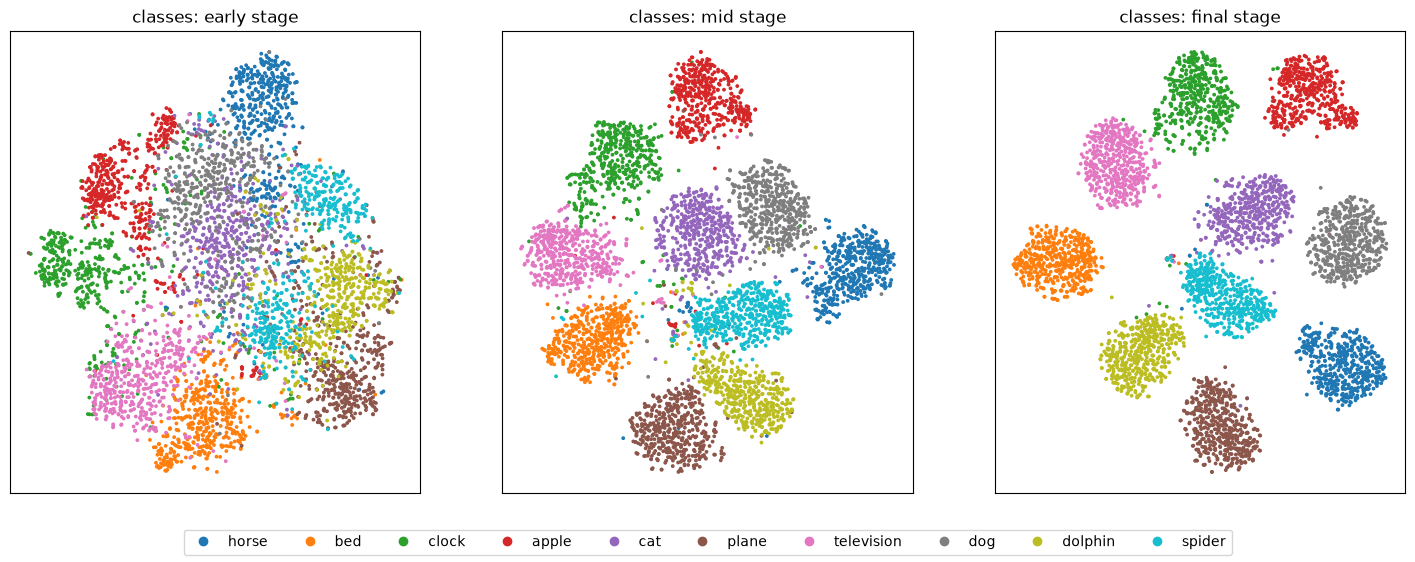

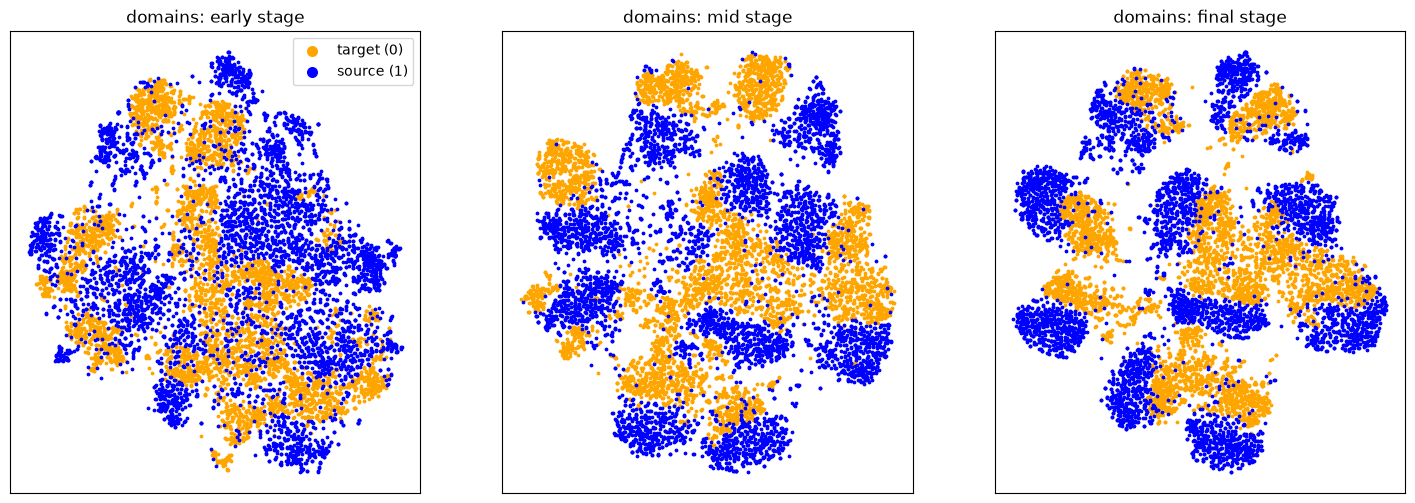

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, stage in zip(axes, STAGES):
    X_norm, y = tsne_class[stage], stage_feats[stage][1]
    sc = ax.scatter(X_norm[:, 0], X_norm[:, 1], c=y, cmap="tab10", s=3)
    ax.set_title(f"classes: {stage} stage")
    ax.set_xticks([]); ax.set_yticks([])
handles = [plt.Line2D([], [], marker="o", ls="", color=plt.cm.tab10(i), label=t) for i, t in enumerate(titles)]
fig.legend(handles=handles, loc="lower center", ncol=10)
plt.savefig("tsne_class.png", dpi=150, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, stage in zip(axes, STAGES):
    X_norm = tsne_domain[stage]
    n_src = len(stage_feats[stage][0])
    ax.scatter(X_norm[n_src:, 0], X_norm[n_src:, 1], c="orange", s=3, label="target (0)")
    ax.scatter(X_norm[:n_src, 0], X_norm[:n_src, 1], c="blue", s=3, label="source (1)")
    ax.set_title(f"domains: {stage} stage")
    ax.set_xticks([]); ax.set_yticks([])
axes[0].legend(markerscale=4)
plt.savefig("tsne_domain.png", dpi=150, bbox_inches="tight")
plt.show()